# Layer Normalization — From Scratch

**Paper:** Ba, J. L., Kiros, J. R., & Hinton, G. E. (2016). *Layer Normalization.* [arXiv:1607.06450](https://arxiv.org/abs/1607.06450)

This notebook implements Layer Normalization from scratch (NumPy with a gradient check, then PyTorch), compares no normalization, BatchNorm and LayerNorm inside a simple RNN on a toy sequence task, trains a small Transformer block that uses LayerNorm, and tests training with batch size 1.

**All computation runs on CPU — no GPU required.** The Summary at the end says what this run found.

## 1. Imports & Setup


In [1]:
import atexit
import copy
import os
import shutil

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats

# Show figures as JPEG at a modest resolution to keep the saved notebook small
set_matplotlib_formats('jpeg')
plt.rcParams['figure.dpi'] = 80

# On Kaggle (detected from its environment), keep a copy of this notebook with its outputs when
# the kernel exits, so `kaggle kernels output` can download the executed version
if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ:
    atexit.register(lambda: os.path.exists('__notebook__.ipynb')
                    and shutil.copy('__notebook__.ipynb', 'executed_solution.ipynb'))

torch.manual_seed(42)
np.random.seed(42)
# One CPU thread and deterministic kernels, so results do not depend on the machine's core count
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

device = torch.device('cpu')
print(f"Device: {device}")

Device: cpu


## 2. LayerNorm from Scratch in NumPy

We implement LayerNorm in pure NumPy to understand the math, then verify gradients with finite differences.

**Formula:** For a layer with H hidden units, given summed inputs `a` (shape H):
- μ = (1/H) Σ aᵢ
- σ² = (1/H) Σ (aᵢ - μ)²
- āᵢ = gᵢ · (aᵢ - μ) / √(σ² + ε) + bᵢ

where g (gain) and b (bias) are learnable per-feature parameters.


In [2]:
def layer_norm_numpy(x, gain, bias, eps=1e-5):
    """LayerNorm in pure NumPy.
    
    Args:
        x: (H,) array of summed inputs to a layer for one sample
        gain: (H,) learnable scale parameters
        bias: (H,) learnable shift parameters
        eps: small constant for numerical stability
    
    Returns:
        Normalized output (H,)
    """
    mu = np.mean(x)
    var = np.var(x)
    x_norm = (x - mu) / np.sqrt(var + eps)
    out = gain * x_norm + bias
    return out

# Test: verify normalization properties
H = 64
x_test = np.random.randn(H) * 10 + 5  # arbitrary scale and shift
gain_test = np.ones(H)
bias_test = np.zeros(H)

out_test = layer_norm_numpy(x_test, gain_test, bias_test)
print(f"Input  — mean: {x_test.mean():.4f}, std: {x_test.std():.4f}")
print(f"Output — mean: {out_test.mean():.4f}, std: {out_test.std():.4f}")
print(f"Output should have ~0 mean and ~1 std")
assert abs(out_test.mean()) < 1e-5, "Mean not zero!"
assert abs(out_test.std() - 1.0) < 1e-3, "Std not one!"
print("✓ LayerNorm NumPy implementation verified!")


Input  — mean: 3.0865, std: 8.9014
Output — mean: -0.0000, std: 1.0000
Output should have ~0 mean and ~1 std
✓ LayerNorm NumPy implementation verified!


### Gradient Check (Finite Differences)


In [3]:
def layer_norm_backward_numpy(x, gain, bias, eps=1e-5):
    """Compute analytic gradients for LayerNorm.
    
    Given upstream gradient dout (same shape as output),
    returns gradients for x, gain, and bias.
    """
    mu = np.mean(x)
    var = np.var(x)
    std = np.sqrt(var + eps)
    x_norm = (x - mu) / std
    
    # We'll use a simple loss = sum(output) for gradient checking
    # dL/dout = 1 for all elements
    dout = np.ones_like(x)
    
    # dL/dbias = dout
    dbias = dout.copy()
    
    # dL/dgain = dout * x_norm
    dgain = dout * x_norm
    
    # dL/dx_norm = dout * gain
    dx_norm = dout * gain
    
    # dL/dx = (1/std) * (dx_norm - mean(dx_norm) - x_norm * mean(dx_norm * x_norm))
    H = len(x)
    dx = (1.0 / std) * (dx_norm - np.mean(dx_norm) - x_norm * np.mean(dx_norm * x_norm))
    
    return dx, dgain, dbias

# Finite difference gradient check
H = 32
x = np.random.randn(H)
gain = np.random.randn(H) * 0.5 + 1
bias = np.random.randn(H) * 0.1
eps = 1e-5

# Analytic gradients
dx_analytic, dgain_analytic, dbias_analytic = layer_norm_backward_numpy(x, gain, bias, eps)

# Numerical gradients
def loss_fn(x, gain, bias, eps=1e-5):
    return np.sum(layer_norm_numpy(x, gain, bias, eps))

dx_numerical = np.zeros(H)
for i in range(H):
    x_plus = x.copy(); x_plus[i] += 1e-6
    x_minus = x.copy(); x_minus[i] -= 1e-6
    dx_numerical[i] = (loss_fn(x_plus, gain, bias, eps) - loss_fn(x_minus, gain, bias, eps)) / 2e-6

dgain_numerical = np.zeros(H)
for i in range(H):
    g_plus = gain.copy(); g_plus[i] += 1e-6
    g_minus = gain.copy(); g_minus[i] -= 1e-6
    dgain_numerical[i] = (loss_fn(x, g_plus, bias, eps) - loss_fn(x, g_minus, bias, eps)) / 2e-6

dbias_numerical = np.zeros(H)
for i in range(H):
    b_plus = bias.copy(); b_plus[i] += 1e-6
    b_minus = bias.copy(); b_minus[i] -= 1e-6
    dbias_numerical[i] = (loss_fn(x, gain, b_plus, eps) - loss_fn(x, gain, b_minus, eps)) / 2e-6

# Check relative error
def rel_error(a, b):
    return np.max(np.abs(a - b) / (np.maximum(1e-8, np.abs(a) + np.abs(b))))

print(f"dx    relative error: {rel_error(dx_analytic, dx_numerical):.2e}")
print(f"dgain relative error: {rel_error(dgain_analytic, dgain_numerical):.2e}")
print(f"dbias relative error: {rel_error(dbias_analytic, dbias_numerical):.2e}")
assert rel_error(dx_analytic, dx_numerical) < 1e-5, "dx gradient check failed!"
assert rel_error(dgain_analytic, dgain_numerical) < 1e-5, "dgain gradient check failed!"
assert rel_error(dbias_analytic, dbias_numerical) < 1e-5, "dbias gradient check failed!"
print("✓ All gradient checks passed!")


dx    relative error: 1.24e-07
dgain relative error: 1.07e-09
dbias relative error: 1.52e-10
✓ All gradient checks passed!


## 3. LayerNorm as a PyTorch Module

Now we implement LayerNorm as a proper PyTorch `nn.Module`, then verify it matches PyTorch's built-in `nn.LayerNorm`.


In [4]:
class LayerNorm(nn.Module):
    """Layer Normalization implemented from scratch in PyTorch.
    
    Normalizes over the last dimension (features) for each sample independently.
    
    Args:
        features: number of features in the last dimension
        eps: small constant for numerical stability
    """
    def __init__(self, features, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.gamma = nn.Parameter(torch.ones(features))  # gain
        self.beta = nn.Parameter(torch.zeros(features))   # bias
        
    def forward(self, x):
        # x shape: (..., features) — normalize over last dim
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        x_norm = (x - mean) / torch.sqrt(var + self.eps)
        return self.gamma * x_norm + self.beta

# Verify against PyTorch's built-in LayerNorm
H = 64
B = 32
x = torch.randn(B, H)

my_ln = LayerNorm(H)
pt_ln = nn.LayerNorm(H)

# Copy parameters to match
my_ln.gamma.data = pt_ln.weight.data.clone()
my_ln.beta.data = pt_ln.bias.data.clone()

out_my = my_ln(x)
out_pt = pt_ln(x)

max_diff = (out_my - out_pt).abs().max().item()
print(f"Max difference between our LayerNorm and PyTorch's nn.LayerNorm: {max_diff:.2e}")
assert max_diff < 1e-6, "Mismatch with PyTorch LayerNorm!"
print("✓ Our LayerNorm matches PyTorch's nn.LayerNorm!")

# Also test with 3D input (batch, seq, features)
x3d = torch.randn(16, 20, H)
out_my3d = my_ln(x3d)
out_pt3d = pt_ln(x3d)
max_diff3d = (out_my3d - out_pt3d).abs().max().item()
print(f"3D input max diff: {max_diff3d:.2e}")
assert max_diff3d < 1e-6
print("✓ Works with 3D input (batch, seq, features)!")


Max difference between our LayerNorm and PyTorch's nn.LayerNorm: 4.77e-07
✓ Our LayerNorm matches PyTorch's nn.LayerNorm!
3D input max diff: 4.77e-07
✓ Works with 3D input (batch, seq, features)!


## 4. BatchNorm for Comparison

We implement a simplified BatchNorm from scratch to compare against LayerNorm. BatchNorm normalizes over the **batch dimension** (dim=0) and maintains running statistics for inference.


In [5]:
class BatchNorm1d(nn.Module):
    """BatchNorm1d implemented from scratch.
    
    Normalizes over the batch dimension (dim=0).
    Maintains running mean/var for inference.
    
    Args:
        features: number of features
        eps: numerical stability
        momentum: running average momentum
    """
    def __init__(self, features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps = eps
        self.momentum = momentum
        self.gamma = nn.Parameter(torch.ones(features))
        self.beta = nn.Parameter(torch.zeros(features))
        # Running stats (not parameters — not learned via gradient)
        self.register_buffer('running_mean', torch.zeros(features))
        self.register_buffer('running_var', torch.ones(features))
        self.training_mode = True
        
    def forward(self, x):
        # x shape: (batch, features)
        if self.training_mode:
            batch_mean = x.mean(dim=0)
            batch_var = x.var(dim=0, unbiased=False)
            # Update running stats
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * batch_mean
                self.running_var = (1 - self.momentum) * self.running_var + self.momentum * batch_var
        else:
            batch_mean = self.running_mean
            batch_var = self.running_var
        
        x_norm = (x - batch_mean) / torch.sqrt(batch_var + self.eps)
        return self.gamma * x_norm + self.beta
    
    def eval(self):
        self.training_mode = False
        return self
    
    def train(self, mode=True):
        self.training_mode = mode
        return self


## 5. Toy Sequence Classification Task

We create a synthetic sequence dataset where:
- **Class 0:** Sequences with an increasing trend + noise
- **Class 1:** Sequences with a decreasing trend + noise

This is an RNN-friendly task that tests whether normalization helps with sequence learning.


Training data:   X_train torch.Size([1000, 20, 64]), y_train torch.Size([1000])
Test data:       X_test  torch.Size([200, 20, 64]), y_test  torch.Size([200])
Classes: [0, 1]
Class distribution (train): [517, 483]


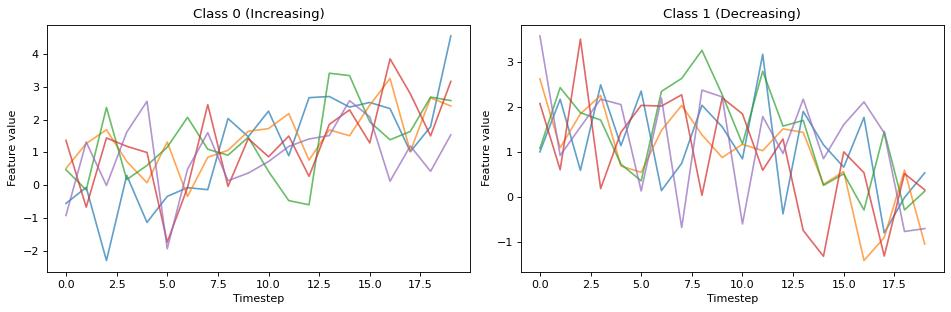

✓ Data generated and visualized!


In [6]:
def generate_sequence_data(n_samples=1000, seq_len=20, n_features=64, seed=42):
    """Generate synthetic sequence classification data.
    
    Class 0: increasing trend + noise
    Class 1: decreasing trend + noise
    """
    rng = np.random.RandomState(seed)
    
    X = np.zeros((n_samples, seq_len, n_features))
    y = np.zeros(n_samples, dtype=np.int64)
    
    for i in range(n_samples):
        label = rng.randint(2)
        y[i] = label
        
        if label == 0:
            # Increasing trend: each timestep's features have slightly higher mean
            trend = np.linspace(0, 2, seq_len)
        else:
            # Decreasing trend
            trend = np.linspace(2, 0, seq_len)
        
        for t in range(seq_len):
            X[i, t, :] = rng.randn(n_features) + trend[t]
    
    return torch.FloatTensor(X), torch.LongTensor(y)

# Generate data
X_train, y_train = generate_sequence_data(n_samples=1000, seed=42)
X_test, y_test = generate_sequence_data(n_samples=200, seed=123)

print(f"Training data:   X_train {X_train.shape}, y_train {y_train.shape}")
print(f"Test data:       X_test  {X_test.shape}, y_test  {y_test.shape}")
print(f"Classes: {y_train.unique().tolist()}")
print(f"Class distribution (train): {torch.bincount(y_train).tolist()}")

# Visualize a sample from each class
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for cls in range(2):
    idx = (y_train == cls).nonzero()[0, 0].item()
    for f in range(5):  # show first 5 features
        axes[cls].plot(X_train[idx, :, f].numpy(), alpha=0.7)
    axes[cls].set_title(f"Class {cls} ({'Increasing' if cls == 0 else 'Decreasing'})")
    axes[cls].set_xlabel("Timestep")
    axes[cls].set_ylabel("Feature value")
plt.tight_layout()
plt.show()
print("✓ Data generated and visualized!")

## 6. Simple RNN with Pluggable Normalization

We build an RNN cell that can use LayerNorm, BatchNorm, or no normalization, then wrap it in a full RNN model.


In [7]:
class RNNCellWithNorm(nn.Module):
    """RNN cell with optional normalization applied to pre-activation.
    
    h_t = tanh(norm(W_hh @ h_{t-1} + W_xh @ x_t))
    
    Args:
        input_size: dimension of input x_t
        hidden_size: dimension of hidden state h_t
        norm_type: 'layer', 'batch', or 'none'
    """
    def __init__(self, input_size, hidden_size, norm_type='layer'):
        super().__init__()
        self.hidden_size = hidden_size
        
        # Weight matrices
        self.W_xh = nn.Linear(input_size, hidden_size, bias=False)
        self.W_hh = nn.Linear(hidden_size, hidden_size, bias=False)
        
        # Normalization
        self.norm_type = norm_type
        if norm_type == 'layer':
            self.norm = LayerNorm(hidden_size)
        elif norm_type == 'batch':
            self.norm = BatchNorm1d(hidden_size)
        else:
            self.norm = None
            
        # Bias (only used when no norm, or added after norm)
        self.bias = nn.Parameter(torch.zeros(hidden_size))
        
        # Initialize weights
        nn.init.xavier_uniform_(self.W_xh.weight)
        nn.init.orthogonal_(self.W_hh.weight)
    
    def forward(self, x_t, h_prev):
        # Compute pre-activation
        a_t = self.W_xh(x_t) + self.W_hh(h_prev)
        
        # Apply normalization
        if self.norm_type == 'batch':
            # BatchNorm expects (batch, features)
            a_t = self.norm(a_t)
        elif self.norm_type == 'layer':
            a_t = self.norm(a_t)
        else:
            a_t = a_t + self.bias
        
        # Non-linearity
        h_t = torch.tanh(a_t)
        return h_t


class SimpleRNN(nn.Module):
    """Full RNN model for sequence classification.
    
    Unrolls RNN cell over T timesteps, uses final hidden state for classification.
    """
    def __init__(self, input_size, hidden_size, n_classes=2, norm_type='layer'):
        super().__init__()
        self.hidden_size = hidden_size
        self.cell = RNNCellWithNorm(input_size, hidden_size, norm_type)
        self.classifier = nn.Linear(hidden_size, n_classes)
    
    def forward(self, x):
        # x shape: (batch, seq_len, input_size)
        batch_size = x.size(0)
        seq_len = x.size(1)
        
        # Initialize hidden state
        h = torch.zeros(batch_size, self.hidden_size)
        
        # Unroll over timesteps
        for t in range(seq_len):
            h = self.cell(x[:, t, :], h)
        
        # Classify from final hidden state
        logits = self.classifier(h)
        return logits


## 7. Training Loop — Comparing NoNorm, BatchNorm, and LayerNorm

We train three RNN models with the same architecture and settings, differing only in the normalization applied to the summed inputs at each step. In this simplified BatchNorm, one set of statistics is shared across all time steps (the paper notes that BatchNorm in RNNs needs separate statistics for each time step).

In [8]:
def train_and_evaluate(norm_type, X_train, y_train, X_test, y_test, 
                         epochs=50, lr=0.001, batch_size=64, hidden_size=64):
    """Train an RNN with given normalization and return training history."""
    
    input_size = X_train.size(2)
    n_classes = 2
    
    model = SimpleRNN(input_size, hidden_size, n_classes, norm_type)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    
    n_train = X_train.size(0)
    history = {'loss': [], 'train_acc': [], 'test_acc': []}
    
    for epoch in range(epochs):
        # Shuffle training data
        perm = torch.randperm(n_train)
        epoch_loss = 0.0
        n_batches = 0
        
        model.train()
        for i in range(0, n_train, batch_size):
            idx = perm[i:i+batch_size]
            xb, yb = X_train[idx], y_train[idx]
            
            logits = model(xb)
            loss = criterion(logits, yb)
            
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()
            
            epoch_loss += loss.item()
            n_batches += 1
        
        avg_loss = epoch_loss / n_batches
        
        # Evaluate
        model.eval()
        with torch.no_grad():
            # Training accuracy
            train_logits = model(X_train)
            train_pred = train_logits.argmax(dim=1)
            train_acc = (train_pred == y_train).float().mean().item()
            
            # Test accuracy
            test_logits = model(X_test)
            test_pred = test_logits.argmax(dim=1)
            test_acc = (test_pred == y_test).float().mean().item()
        
        history['loss'].append(avg_loss)
        history['train_acc'].append(train_acc)
        history['test_acc'].append(test_acc)
        
        if (epoch + 1) % 10 == 0:
            print(f"  [{norm_type:>6s}] Epoch {epoch+1:3d}/{epochs} | "
                  f"Loss: {avg_loss:.4f} | Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")
    
    return model, history

# Train all three models
print("Training NoNorm RNN...")
model_none, hist_none = train_and_evaluate('none', X_train, y_train, X_test, y_test)

print("\nTraining BatchNorm RNN...")
model_bn, hist_bn = train_and_evaluate('batch', X_train, y_train, X_test, y_test)

print("\nTraining LayerNorm RNN...")
model_ln, hist_ln = train_and_evaluate('layer', X_train, y_train, X_test, y_test)

print(f"\n{'='*60}")
print(f"Final Test Accuracies:")
print(f"  NoNorm:    {hist_none['test_acc'][-1]:.4f}")
print(f"  BatchNorm: {hist_bn['test_acc'][-1]:.4f}")
print(f"  LayerNorm: {hist_ln['test_acc'][-1]:.4f}")
print(f"{'='*60}")


Training NoNorm RNN...


  [  none] Epoch  10/50 | Loss: 0.0027 | Train Acc: 1.0000 | Test Acc: 1.0000


  [  none] Epoch  20/50 | Loss: 0.0009 | Train Acc: 1.0000 | Test Acc: 1.0000


  [  none] Epoch  30/50 | Loss: 0.0005 | Train Acc: 1.0000 | Test Acc: 1.0000


  [  none] Epoch  40/50 | Loss: 0.0003 | Train Acc: 1.0000 | Test Acc: 1.0000


  [  none] Epoch  50/50 | Loss: 0.0002 | Train Acc: 1.0000 | Test Acc: 1.0000

Training BatchNorm RNN...


... (6 outputs left out)

  [ layer] Epoch  20/50 | Loss: 0.0010 | Train Acc: 1.0000 | Test Acc: 1.0000


  [ layer] Epoch  30/50 | Loss: 0.0005 | Train Acc: 1.0000 | Test Acc: 1.0000


  [ layer] Epoch  40/50 | Loss: 0.0003 | Train Acc: 1.0000 | Test Acc: 1.0000


  [ layer] Epoch  50/50 | Loss: 0.0002 | Train Acc: 1.0000 | Test Acc: 1.0000

Final Test Accuracies:
  NoNorm:    1.0000
  BatchNorm: 1.0000
  LayerNorm: 1.0000


## 8. Transformer Block with LayerNorm

LayerNorm is a core part of the Transformer. We implement a small pre-norm Transformer block (LayerNorm before self-attention and before the feed-forward network) and train it on the same task.

Self-attention followed by mean pooling ignores the order of the time steps, but this task is all about order (an increasing vs a decreasing trend). So the model adds a learned **positional embedding** to each time step, as Transformers do. An earlier version of this notebook had no positional information: its training loss went to almost zero while its test accuracy stayed at chance, because it could only memorize noise.

In [9]:
class SimpleSelfAttention(nn.Module):
    """Single-head self-attention (simplified)."""
    def __init__(self, embed_dim):
        super().__init__()
        self.q = nn.Linear(embed_dim, embed_dim)
        self.k = nn.Linear(embed_dim, embed_dim)
        self.v = nn.Linear(embed_dim, embed_dim)
        self.scale = embed_dim ** -0.5
    
    def forward(self, x):
        # x: (batch, seq_len, embed_dim)
        Q = self.q(x)
        K = self.k(x)
        V = self.v(x)
        
        # Scaled dot-product attention
        scores = torch.bmm(Q, K.transpose(1, 2)) * self.scale  # (batch, seq, seq)
        attn = F.softmax(scores, dim=-1)
        out = torch.bmm(attn, V)  # (batch, seq, embed_dim)
        return out


class TransformerBlock(nn.Module):
    """Simplified Transformer block with pre-norm LayerNorm.
    
    Architecture (pre-norm):
        x -> LayerNorm -> Self-Attention -> residual -> LayerNorm -> FFN -> residual
    
    This is the style used in GPT-2 and most modern transformers.
    """
    def __init__(self, embed_dim, ff_dim):
        super().__init__()
        # Pre-norm: LayerNorm before attention and FFN
        self.ln1 = LayerNorm(embed_dim)
        self.attn = SimpleSelfAttention(embed_dim)
        self.ln2 = LayerNorm(embed_dim)
        self.ffn = nn.Sequential(
            nn.Linear(embed_dim, ff_dim),
            nn.GELU(),
            nn.Linear(ff_dim, embed_dim)
        )
    
    def forward(self, x):
        # x: (batch, seq_len, embed_dim)
        
        # Pre-norm attention with residual
        x = x + self.attn(self.ln1(x))
        
        # Pre-norm FFN with residual
        x = x + self.ffn(self.ln2(x))
        
        return x


class TransformerClassifier(nn.Module):
    """Simple transformer-based sequence classifier."""
    def __init__(self, input_size, embed_dim, ff_dim, n_classes=2, seq_len=20):
        super().__init__()
        self.input_proj = nn.Linear(input_size, embed_dim)
        # Learned positional embedding: without it, attention + mean pooling cannot see the order of time steps
        self.pos_emb = nn.Parameter(torch.randn(1, seq_len, embed_dim) * 0.02)
        self.transformer = TransformerBlock(embed_dim, ff_dim)
        self.ln_final = LayerNorm(embed_dim)
        self.classifier = nn.Linear(embed_dim, n_classes)
    
    def forward(self, x):
        # x: (batch, seq_len, input_size)
        x = self.input_proj(x) + self.pos_emb  # (batch, seq_len, embed_dim)
        x = self.transformer(x)  # (batch, seq_len, embed_dim)
        x = self.ln_final(x)     # Final LayerNorm
        # Pool: mean over sequence dimension
        x = x.mean(dim=1)        # (batch, embed_dim)
        logits = self.classifier(x)
        return logits

# Train the Transformer classifier
print("Training Transformer with LayerNorm...")
tf_model = TransformerClassifier(input_size=64, embed_dim=64, ff_dim=128, n_classes=2, seq_len=X_train.size(1))
tf_optimizer = torch.optim.Adam(tf_model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

tf_history = {'loss': [], 'test_acc': []}
batch_size = 64
n_train = X_train.size(0)

for epoch in range(50):
    perm = torch.randperm(n_train)
    epoch_loss = 0.0
    n_batches = 0
    
    tf_model.train()
    for i in range(0, n_train, batch_size):
        idx = perm[i:i+batch_size]
        xb, yb = X_train[idx], y_train[idx]
        
        logits = tf_model(xb)
        loss = criterion(logits, yb)
        
        tf_optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(tf_model.parameters(), 5.0)
        tf_optimizer.step()
        
        epoch_loss += loss.item()
        n_batches += 1
    
    avg_loss = epoch_loss / n_batches
    tf_model.eval()
    with torch.no_grad():
        test_logits = tf_model(X_test)
        test_acc = (test_logits.argmax(dim=1) == y_test).float().mean().item()
    
    tf_history['loss'].append(avg_loss)
    tf_history['test_acc'].append(test_acc)
    
    if (epoch + 1) % 10 == 0:
        print(f"  [Transformer] Epoch {epoch+1:3d}/50 | Loss: {avg_loss:.4f} | Test Acc: {test_acc:.4f}")

print(f"\nTransformer final test accuracy: {tf_history['test_acc'][-1]:.4f}")

Training Transformer with LayerNorm...


  [Transformer] Epoch  10/50 | Loss: 0.0005 | Test Acc: 1.0000


  [Transformer] Epoch  20/50 | Loss: 0.0003 | Test Acc: 1.0000


  [Transformer] Epoch  30/50 | Loss: 0.0002 | Test Acc: 1.0000


  [Transformer] Epoch  40/50 | Loss: 0.0001 | Test Acc: 1.0000


  [Transformer] Epoch  50/50 | Loss: 0.0001 | Test Acc: 1.0000

Transformer final test accuracy: 1.0000


## 9. Visualization & Comparison

Training loss and test accuracy for all models, and the average magnitude of the RNN hidden state over the 20 time steps for one test sequence.

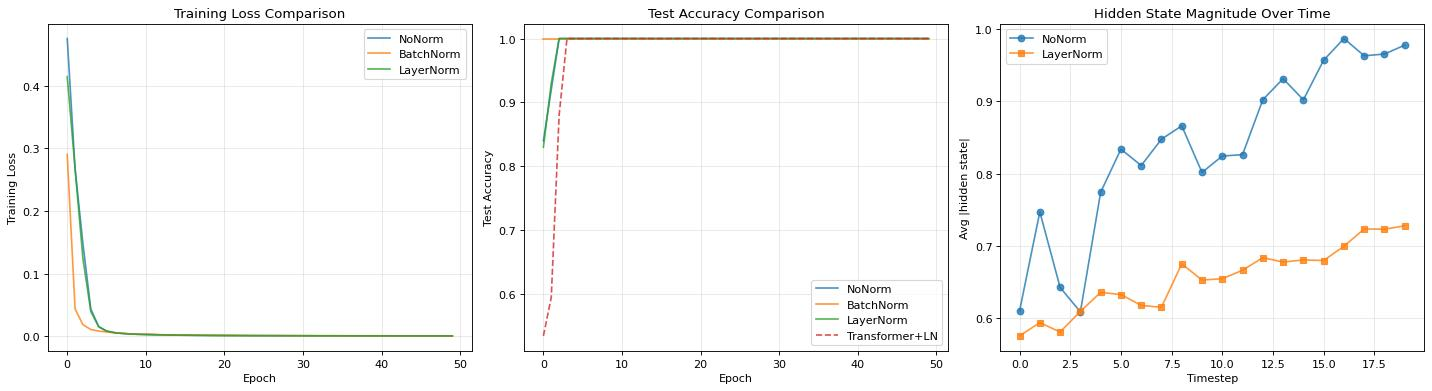

Avg |hidden state|, NoNorm:    step 1 0.610, step 20 0.978
Avg |hidden state|, LayerNorm: step 1 0.576, step 20 0.728
NoNorm     first epoch with test accuracy >= 0.99: 3, loss after epoch 1: 0.4759
BatchNorm  first epoch with test accuracy >= 0.99: 1, loss after epoch 1: 0.2905
LayerNorm  first epoch with test accuracy >= 0.99: 3, loss after epoch 1: 0.4150


In [10]:
# Plot 1: Training Loss Comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(hist_none['loss'], label='NoNorm', alpha=0.8)
axes[0].plot(hist_bn['loss'], label='BatchNorm', alpha=0.8)
axes[0].plot(hist_ln['loss'], label='LayerNorm', alpha=0.8)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Training Loss')
axes[0].set_title('Training Loss Comparison')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Test Accuracy Comparison
axes[1].plot(hist_none['test_acc'], label='NoNorm', alpha=0.8)
axes[1].plot(hist_bn['test_acc'], label='BatchNorm', alpha=0.8)
axes[1].plot(hist_ln['test_acc'], label='LayerNorm', alpha=0.8)
axes[1].plot(tf_history['test_acc'], label='Transformer+LN', alpha=0.8, linestyle='--')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Test Accuracy')
axes[1].set_title('Test Accuracy Comparison')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Plot 3: Hidden state magnitude over timesteps
def get_hidden_states(model, x_sample):
    """Track hidden state magnitudes over timesteps for a single sample."""
    h = torch.zeros(1, model.hidden_size)
    magnitudes = []
    for t in range(x_sample.size(0)):
        h = model.cell(x_sample[t:t+1].unsqueeze(0), h)
        magnitudes.append(h.abs().mean().item())
    return magnitudes

# Get hidden states for a sample from each model
sample = X_test[0]  # Take first test sample
mags_none = get_hidden_states(model_none, sample)
mags_ln = get_hidden_states(model_ln, sample)

axes[2].plot(mags_none, label='NoNorm', alpha=0.8, marker='o')
axes[2].plot(mags_ln, label='LayerNorm', alpha=0.8, marker='s')
axes[2].set_xlabel('Timestep')
axes[2].set_ylabel('Avg |hidden state|')
axes[2].set_title('Hidden State Magnitude Over Time')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print(f"Avg |hidden state|, NoNorm:    step 1 {mags_none[0]:.3f}, step 20 {mags_none[-1]:.3f}")
print(f"Avg |hidden state|, LayerNorm: step 1 {mags_ln[0]:.3f}, step 20 {mags_ln[-1]:.3f}")
for name, h in [('NoNorm', hist_none), ('BatchNorm', hist_bn), ('LayerNorm', hist_ln)]:
    first = next(i for i, a in enumerate(h['test_acc']) if a >= 0.99) + 1
    print(f"{name:<10} first epoch with test accuracy >= 0.99: {first}, loss after epoch 1: {h['loss'][0]:.4f}")

## 10. Batch Size Sensitivity Test

LayerNorm computes its statistics from a single example, so it does not depend on the batch size. Here we train all three RNNs with batch_size=1 (online learning), where BatchNorm's per-batch statistics come from a single example.

Training with batch_size=1 (online learning)...
  This tests whether normalization depends on batch statistics...



  [  none] Epoch  10/20 | Loss: 0.0000 | Train Acc: 1.0000 | Test Acc: 1.0000


  [  none] Epoch  20/20 | Loss: 0.0000 | Train Acc: 1.0000 | Test Acc: 1.0000


  [ batch] Epoch  10/20 | Loss: 0.6937 | Train Acc: 0.7680 | Test Acc: 0.7950


  [ batch] Epoch  20/20 | Loss: 0.6938 | Train Acc: 0.3210 | Test Acc: 0.3250


  [ layer] Epoch  10/20 | Loss: 0.0000 | Train Acc: 1.0000 | Test Acc: 1.0000


  [ layer] Epoch  20/20 | Loss: 0.0000 | Train Acc: 1.0000 | Test Acc: 1.0000

Batch Size = 1 Results (after 20 epochs):
  NoNorm:     Test Acc = 1.0000
  BatchNorm:  Test Acc = 0.3250
  LayerNorm:  Test Acc = 1.0000


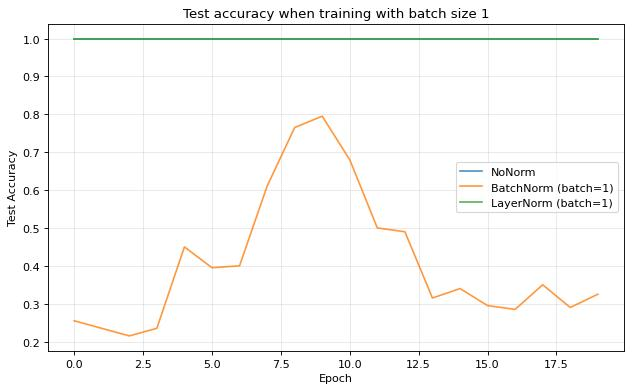

In [11]:
# Train with batch_size=1 (extreme online learning scenario)
print("Training with batch_size=1 (online learning)...")
print("  This tests whether normalization depends on batch statistics...\n")

_, hist_none_b1 = train_and_evaluate('none', X_train, y_train, X_test, y_test, 
                                      epochs=20, batch_size=1)
_, hist_bn_b1 = train_and_evaluate('batch', X_train, y_train, X_test, y_test, 
                                    epochs=20, batch_size=1)
_, hist_ln_b1 = train_and_evaluate('layer', X_train, y_train, X_test, y_test, 
                                    epochs=20, batch_size=1)

print(f"\n{'='*60}")
print(f"Batch Size = 1 Results (after 20 epochs):")
print(f"  NoNorm:     Test Acc = {hist_none_b1['test_acc'][-1]:.4f}")
print(f"  BatchNorm:  Test Acc = {hist_bn_b1['test_acc'][-1]:.4f}")
print(f"  LayerNorm:  Test Acc = {hist_ln_b1['test_acc'][-1]:.4f}")
print(f"{'='*60}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(hist_none_b1['test_acc'], label='NoNorm', alpha=0.8)
ax.plot(hist_bn_b1['test_acc'], label='BatchNorm (batch=1)', alpha=0.8)
ax.plot(hist_ln_b1['test_acc'], label='LayerNorm (batch=1)', alpha=0.8)
ax.set_xlabel('Epoch')
ax.set_ylabel('Test Accuracy')
ax.set_title('Test accuracy when training with batch size 1')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
print("=" * 70)
print("LAYER NORMALIZATION — EXPERIMENT SUMMARY")
print("=" * 70)
print()
print("Experiment 1: RNN Sequence Classification (batch_size=64, 50 epochs)")
print(f"  NoNorm      — Final Test Accuracy: {hist_none['test_acc'][-1]:.4f}")
print(f"  BatchNorm   — Final Test Accuracy: {hist_bn['test_acc'][-1]:.4f}")
print(f"  LayerNorm   — Final Test Accuracy: {hist_ln['test_acc'][-1]:.4f}")
print()
print("Experiment 2: Transformer with LayerNorm (50 epochs)")
print(f"  Transformer — Final Test Accuracy: {tf_history['test_acc'][-1]:.4f}")
print()
print("Experiment 3: Batch Size Sensitivity (batch_size=1, 20 epochs)")
print(f"  NoNorm      — Final Test Accuracy: {hist_none_b1['test_acc'][-1]:.4f}")
print(f"  BatchNorm   — Final Test Accuracy: {hist_bn_b1['test_acc'][-1]:.4f}")
print(f"  LayerNorm   — Final Test Accuracy: {hist_ln_b1['test_acc'][-1]:.4f}")
print()
print("=" * 70)

LAYER NORMALIZATION — EXPERIMENT SUMMARY

Experiment 1: RNN Sequence Classification (batch_size=64, 50 epochs)
  NoNorm      — Final Test Accuracy: 1.0000
  BatchNorm   — Final Test Accuracy: 1.0000
  LayerNorm   — Final Test Accuracy: 1.0000

Experiment 2: Transformer with LayerNorm (50 epochs)
  Transformer — Final Test Accuracy: 1.0000

Experiment 3: Batch Size Sensitivity (batch_size=1, 20 epochs)
  NoNorm      — Final Test Accuracy: 1.0000
  BatchNorm   — Final Test Accuracy: 0.3250
  LayerNorm   — Final Test Accuracy: 1.0000



## 11. Summary

### What the run above shows

- **The from-scratch LayerNorm is correct.** Its output has mean 0 and standard deviation 1, the analytic gradients match finite differences (largest relative error 1.24e-07 for the inputs), and it matches PyTorch's `nn.LayerNorm` to 4.77e-07.
- **The RNN task is too easy to separate the methods.** With batch size 64, the RNNs without normalization, with BatchNorm and with LayerNorm all reach 100% test accuracy, with almost the same final loss (0.0002–0.0003). BatchNorm passed 99% test accuracy after 1 epoch, the other two after 3, and BatchNorm also had the lowest loss after epoch 1 (0.2905, vs 0.4150 for LayerNorm and 0.4759 without normalization). So this run gives no evidence that LayerNorm trains faster; the paper's speed-ups come from much harder tasks.
- **Hidden state magnitude:** for one test sequence, the average |hidden state| of the LayerNorm RNN grows less over the 20 steps (0.576 → 0.728) than without normalization (0.610 → 0.978). It still grows; it is not constant.
- **The Transformer block works** once it has a positional embedding: 100% test accuracy, with LayerNorm before attention and before the feed-forward network.
- **Batch size 1:** BatchNorm learns nothing: its training loss stays at about 0.693 (ln 2, the loss of random guessing), because with a single example each unit's batch mean equals its own value, so the normalized value is always 0 during training. Its test accuracy, printed above, is therefore close to chance and changes from run to run (62.0%, 32.5% and 57.5% in three runs while preparing this notebook). LayerNorm reaches 100%, but so does the RNN without normalization, so this only shows that BatchNorm breaks at batch size 1, not that LayerNorm beats no normalization.

All experiments use a synthetic task (64 noisy features whose mean rises or falls over 20 steps), so none of these numbers reflect the paper's results on real tasks.
